In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
d1 = pd.read_csv("mir155_toxicity/ProTox-3.0 - Prediction of TOXicity of chemicals-1.csv")


In [2]:
d1 = d1.T
col1 =  d1.iloc[1]
d1_probability = d1[4:]
d1_probability.columns = col1
d1_prediction = d1[3:4]
d1_prediction.columns = col1

d3_prediction = pd.DataFrame()
d3_probability = pd.DataFrame()
fid = []
fid.append(1)
for file in sorted(os.listdir("mir155_toxicity/others/")):
    fid.append(int(file.split('chemicals-')[1].split('.csv')[0]))
    d2 = pd.read_csv('mir155_toxicity/others/'+file)
    d2 = d2.T
    col2 =  d2.iloc[1]
    d2_probability = d2[4:]
    d2_probability.columns = col2
    d2_prediction = d2[3:4]
    d2_prediction.columns = col2
    d3_prediction = pd.concat([d1_prediction,d2_prediction])
    d1_prediction = d3_prediction
    
    d3_probability = pd.concat([d1_probability,d2_probability])
    d1_probability = d3_probability

In [3]:

d1_prediction.insert(0,'id', fid)
d1_probability.insert(0,'id', fid)

d1_prediction.dropna(inplace=True)
d1_probability.dropna(inplace=True)

d1_probability

Target,id,Hepatotoxicity,Neurotoxicity,Nephrotoxicity,Respiratory toxicity,Cardiotoxicity,Carcinogenicity,Immunotoxicity,Mutagenicity,Cytotoxicity,...,Pregnane X receptor (PXR),NADH-quinone oxidoreductase (NADHOX),Voltage gated sodium channel (VGSC),Na+/I- symporter (NIS),Cytochrome CYP1A2,Cytochrome CYP2C19,Cytochrome CYP2C9,Cytochrome CYP2D6,Cytochrome CYP3A4,Cytochrome CYP2E1
Probability,1,0.92,0.64,0.68,0.87,0.82,0.52,0.91,0.73,0.75,...,0.62,0.86,0.72,0.8,0.98,0.89,0.84,0.63,0.81,0.99
Probability,10,0.88,0.64,0.62,0.84,0.85,0.54,0.99,0.7,0.77,...,0.65,0.83,0.69,0.81,0.97,0.88,0.81,0.66,0.79,0.99
Probability,100,0.84,0.61,0.66,0.77,0.81,0.53,0.99,0.64,0.78,...,0.55,0.84,0.55,0.87,0.98,0.83,0.73,0.61,0.72,0.99
Probability,101,0.88,0.67,0.53,0.73,0.85,0.52,0.86,0.65,0.72,...,0.6,0.83,0.7,0.88,0.96,0.92,0.82,0.66,0.87,0.99
Probability,102,0.89,0.64,0.67,0.83,0.83,0.51,0.98,0.72,0.8,...,0.56,0.85,0.61,0.86,0.97,0.9,0.79,0.57,0.84,0.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Probability,95,0.88,0.6,0.74,0.76,0.73,0.59,0.94,0.8,0.76,...,0.52,0.85,0.56,0.94,0.96,0.85,0.79,0.53,0.89,0.99
Probability,96,0.88,0.64,0.61,0.84,0.79,0.51,0.94,0.69,0.78,...,0.59,0.87,0.59,0.86,0.97,0.88,0.81,0.53,0.86,0.99
Probability,97,0.87,0.56,0.54,0.79,0.67,0.63,0.99,0.75,0.79,...,0.53,0.84,0.56,0.91,0.98,0.85,0.79,0.51,0.91,0.99
Probability,98,0.89,0.68,0.68,0.75,0.83,0.59,0.99,0.71,0.85,...,0.57,0.88,0.59,0.85,0.98,0.9,0.81,0.53,0.92,0.99


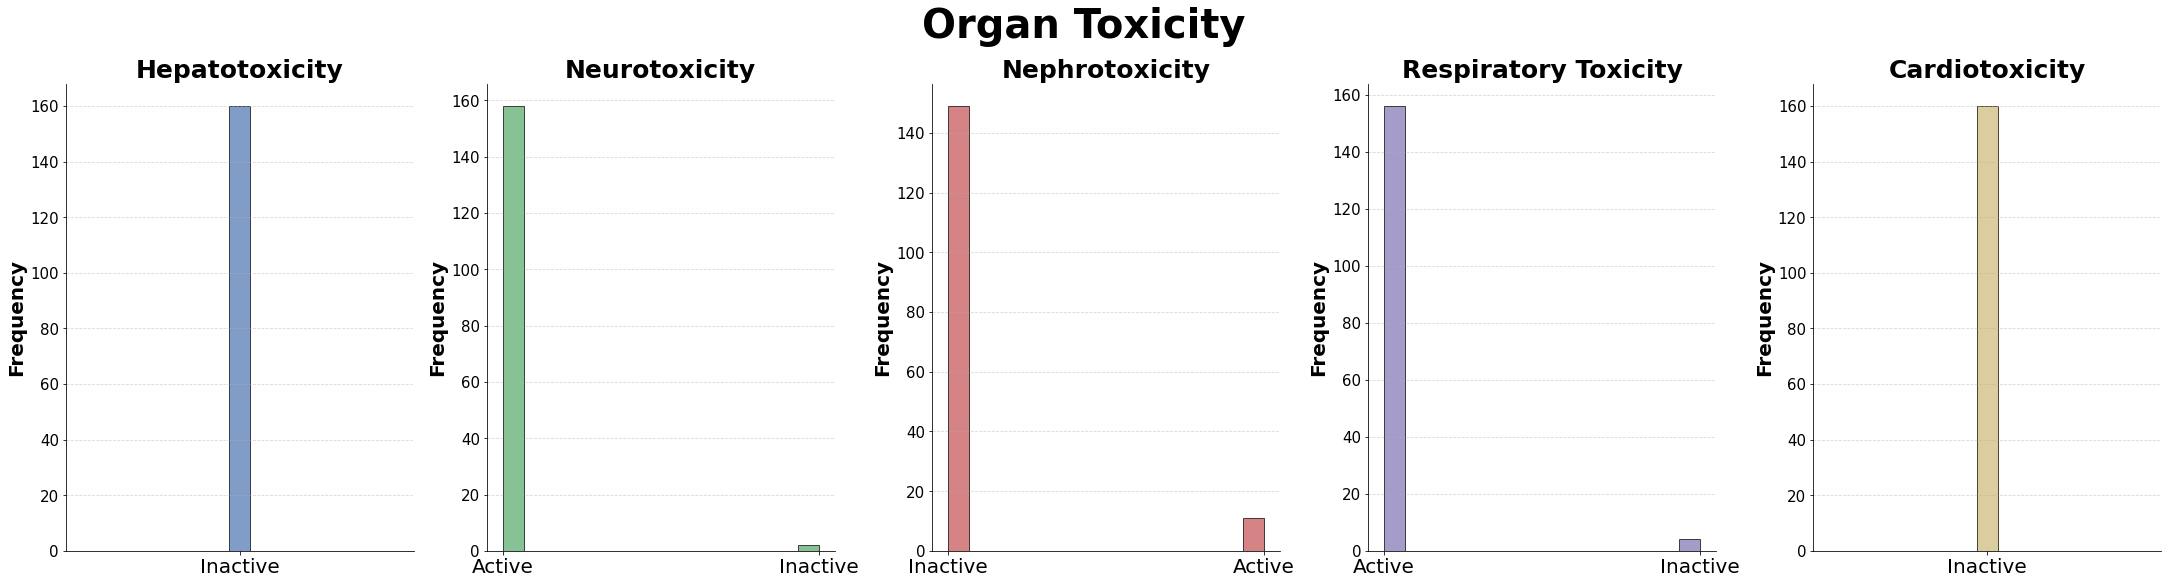

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 5, figsize=(30, 8), constrained_layout=True)

columns = [
    'Hepatotoxicity',
    'Neurotoxicity',
    'Nephrotoxicity',
    'Respiratory toxicity',
    'Cardiotoxicity'
]

titles = [
    'Hepatotoxicity',
    'Neurotoxicity',
    'Nephrotoxicity',
    'Respiratory Toxicity',
    'Cardiotoxicity'
]
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
for i, col in enumerate(columns):
    ax[i].hist(
        d3_prediction[col],
        bins=15,
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )
    
    ax[i].set_title(titles[i], fontsize=25,fontweight='bold')
#     ax[i].set_xlabel('Class', fontsize=20)
    ax[i].set_ylabel('Frequency', fontsize=20,fontweight='bold')
    
    ax[i].grid(axis='y', linestyle='--', alpha=0.5)
    ax[i].tick_params(axis='x',labelsize=20)
    ax[i].tick_params(axis='y',labelsize=15)
    
    # Remove top and right spines for cleaner look
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)

# Optional overall title
fig.suptitle('Organ Toxicity', fontsize=40,fontweight='bold')
plt.savefig("mir155_toxicity/toxicity_plot_mir155_organ_toxicity.png")
plt.show()

In [5]:
# Final clean, robust filtering logic
shortlist = d1_prediction[
    (d1_prediction["Hepatotoxicity"] == "Inactive")
    & (d1_prediction["Cardiotoxicity"] == "Inactive")
    & (d1_prediction["Nephrotoxicity"] == "Inactive")
    & (d1_prediction["Cytotoxicity"] == "Inactive")
    & (d1_prediction["Mutagenicity"] == "Inactive")
    & (d1_prediction["Clinical toxicity"] == "Inactive")
]

shortlist
d1_probability[d1_probability["id"].isin(list(shortlist["id"]))]

Target,id,Hepatotoxicity,Neurotoxicity,Nephrotoxicity,Respiratory toxicity,Cardiotoxicity,Carcinogenicity,Immunotoxicity,Mutagenicity,Cytotoxicity,...,Pregnane X receptor (PXR),NADH-quinone oxidoreductase (NADHOX),Voltage gated sodium channel (VGSC),Na+/I- symporter (NIS),Cytochrome CYP1A2,Cytochrome CYP2C19,Cytochrome CYP2C9,Cytochrome CYP2D6,Cytochrome CYP3A4,Cytochrome CYP2E1
Probability,110,0.91,0.62,0.59,0.82,0.74,0.61,0.73,0.78,0.74,...,0.71,0.88,0.72,0.87,0.93,0.9,0.83,0.52,0.9,0.97
Probability,31,0.92,0.58,0.8,0.7,0.71,0.65,0.84,0.86,0.83,...,0.52,0.82,0.6,0.94,0.98,0.8,0.81,0.59,0.95,0.99
Probability,33,0.9,0.59,0.68,0.67,0.83,0.57,0.92,0.72,0.72,...,0.76,0.75,0.7,0.81,0.81,0.88,0.78,0.6,0.87,0.96
Probability,35,0.89,0.57,0.82,0.57,0.69,0.64,0.97,0.85,0.76,...,0.6,0.77,0.7,0.94,0.96,0.84,0.76,0.62,0.95,0.98
Probability,36,0.93,0.53,0.61,0.81,0.75,0.56,0.89,0.81,0.83,...,0.66,0.78,0.64,0.89,0.95,0.86,0.71,0.54,0.93,0.97
Probability,42,0.92,0.57,0.85,0.68,0.66,0.67,0.62,0.88,0.74,...,0.56,0.77,0.73,0.97,0.94,0.77,0.76,0.64,0.95,0.98
Probability,45,0.88,0.62,0.76,0.68,0.74,0.66,0.84,0.85,0.78,...,0.53,0.76,0.73,0.96,0.92,0.81,0.77,0.64,0.95,0.98
Probability,60,0.86,0.57,0.68,0.69,0.74,0.62,0.99,0.8,0.73,...,0.58,0.77,0.67,0.95,0.96,0.82,0.76,0.56,0.93,0.98
Probability,62,0.89,0.57,0.82,0.57,0.69,0.64,0.97,0.85,0.76,...,0.6,0.77,0.7,0.94,0.96,0.84,0.76,0.62,0.95,0.98
Probability,9,0.81,0.65,0.73,0.67,0.71,0.61,0.99,0.79,0.83,...,0.64,0.82,0.58,0.91,0.93,0.81,0.76,0.58,0.93,0.98


In [6]:
shortlist.to_csv("shortlist_mir155.csv")

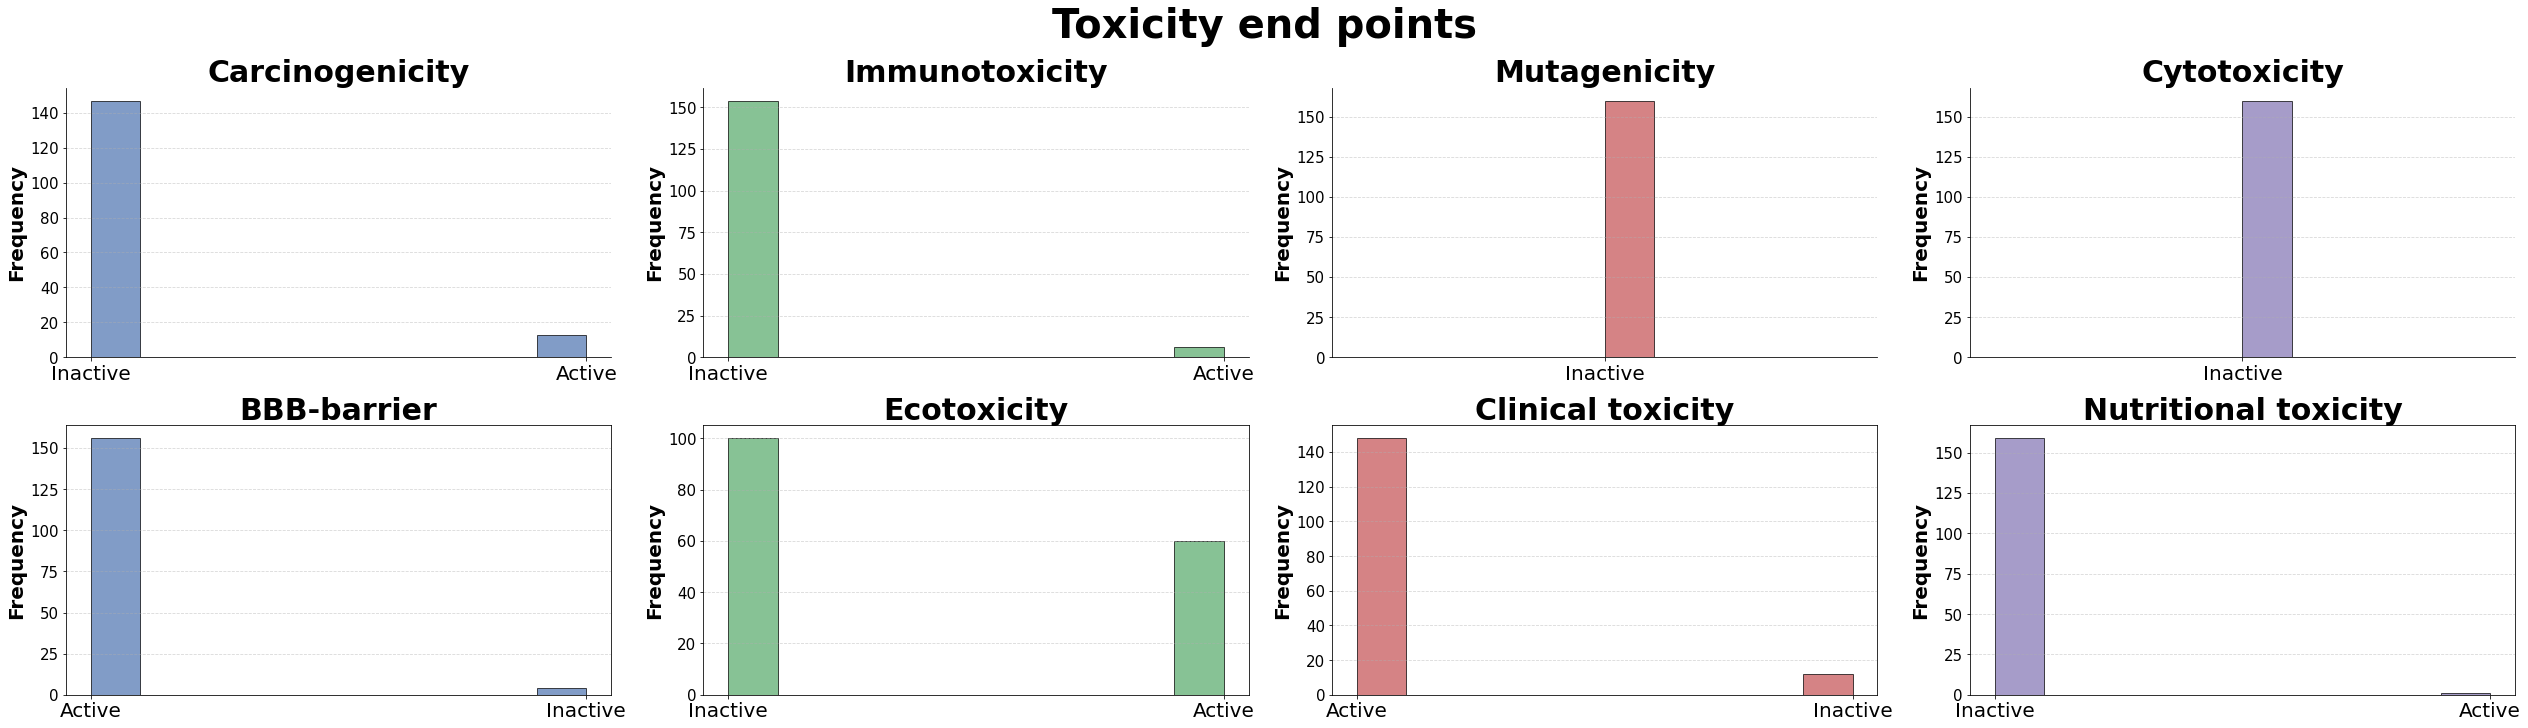

In [7]:

fig, ax = plt.subplots(2, 4, figsize=(35, 10), constrained_layout=True)
# ax.tick_params(axis='both', labelsize=20)

columns = [
'Carcinogenicity',
'Immunotoxicity',
'Mutagenicity',
'Cytotoxicity',
'BBB-barrier',
'Ecotoxicity',
'Clinical toxicity',
'Nutritional toxicity'
]

titles = [
'Carcinogenicity',
'Immunotoxicity',
'Mutagenicity',
'Cytotoxicity',
'BBB-barrier',
'Ecotoxicity',
'Clinical toxicity',
'Nutritional toxicity'
]
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#D68E42', '#949494']
col_no = 0
for i in range(4):
    ax[0,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[0,i].set_title(titles[i], fontsize=30,fontweight='bold')
#     ax[0,i].set_xlabel('Class', fontsize=20)
    ax[0,i].set_ylabel('Frequency', fontsize=20,fontweight='bold')
    ax[0,i].tick_params(axis='x', labelsize=20) # Change 12 to your desired size
    ax[0,i].tick_params(axis='y',labelsize=15)
    
    ax[0,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[0,i].spines['top'].set_visible(False)
    ax[0,i].spines['right'].set_visible(False)
    col_no = col_no+1


col_no = 4    
for i in range(4):
    ax[1,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7,
    )
    ax[1,i].set_title(titles[col_no], fontsize=30,fontweight='bold')
#     ax[1,i].set_xlabel('Class', fontsize=20)
    ax[1,i].set_ylabel('Frequency', fontsize=20,fontweight='bold')
    ax[1,i].tick_params(axis='x', labelsize=20)
    ax[1,i].tick_params(axis='y',labelsize=15)

    
    ax[1,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[0,i].spines['top'].set_visible(False)
    ax[0,i].spines['right'].set_visible(False)
    col_no = col_no+1

# Optional overall title
fig.suptitle('Toxicity end points', fontsize=40,fontweight='bold')
# plt.xticks(fontsize=25)
# plt.yticks(fontsize=25)
plt.savefig("mir155_toxicity/toxicity_plot_mir155_toxicity_endpoints.png")
plt.show()


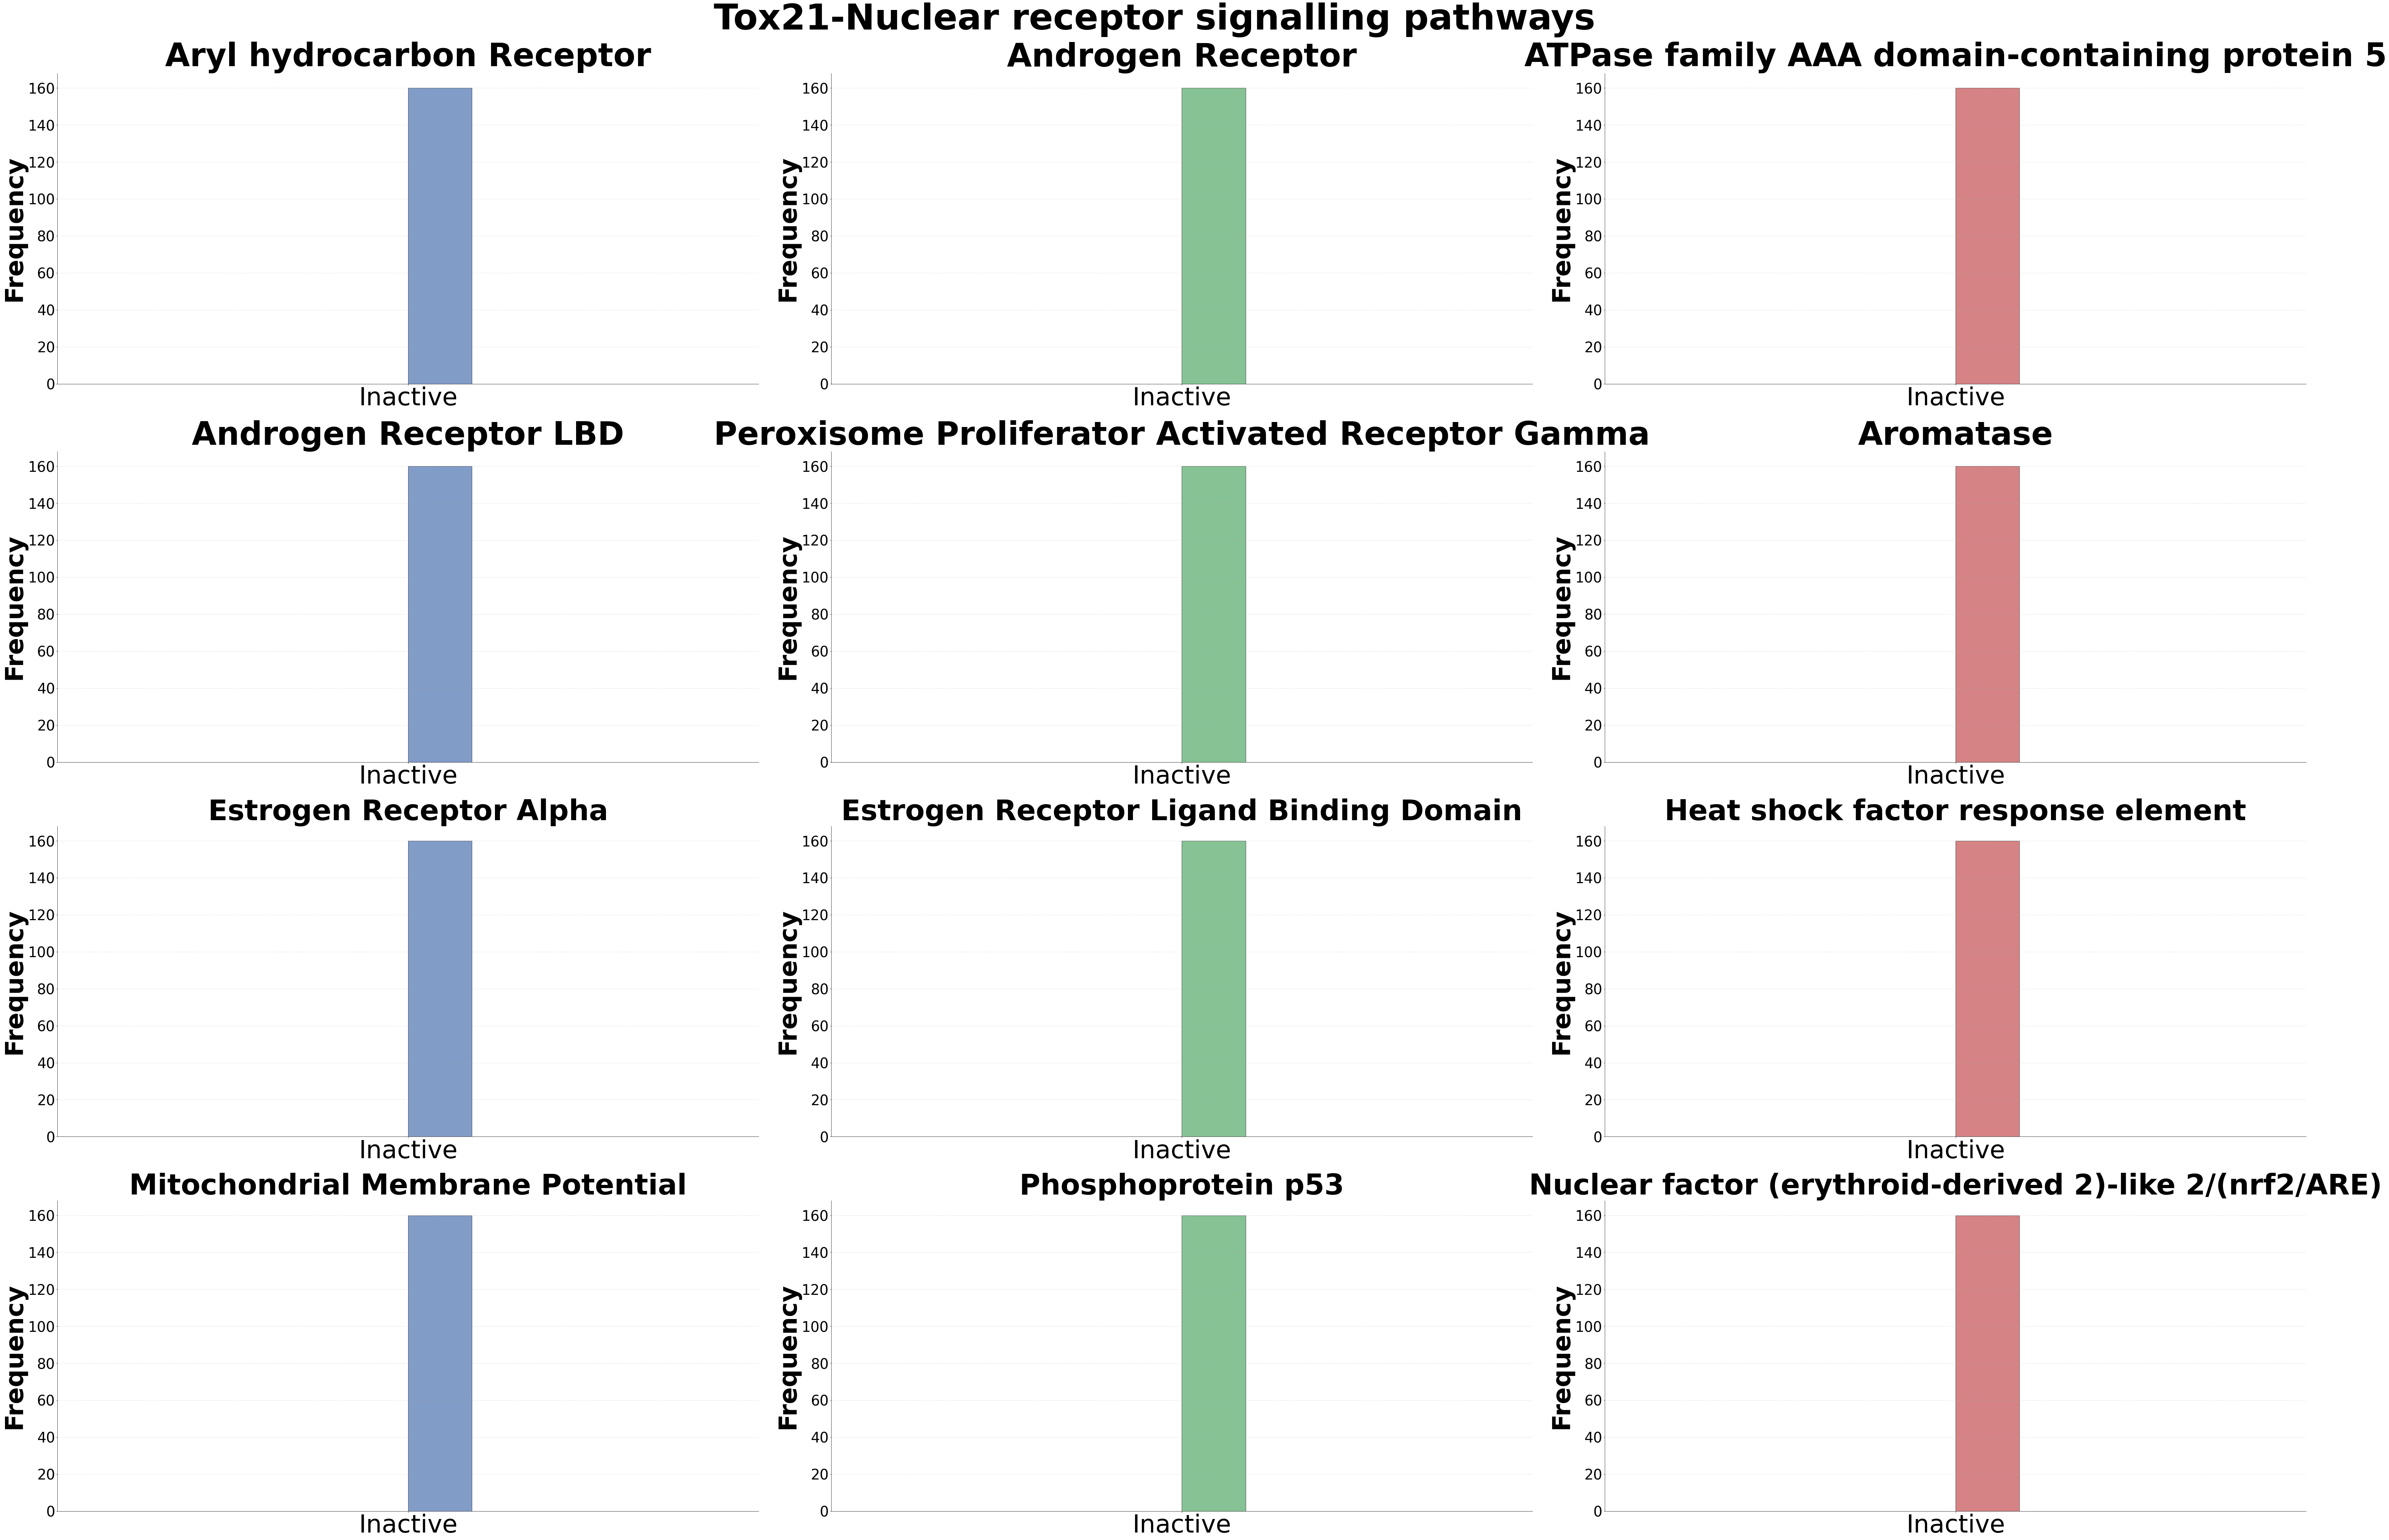

In [8]:

fig, ax = plt.subplots(4, 3, figsize=(90, 60), constrained_layout=True)

columns = [
'Aryl hydrocarbon Receptor (AhR)',
'Androgen Receptor (AR)',
'ATPase family AAA domain-containing protein 5 (ATAD5)',
'Androgen Receptor Ligand Binding Domain (AR-LBD)',
'Peroxisome Proliferator Activated Receptor Gamma (PPAR-Gamma)',
'Aromatase',
'Estrogen Receptor Alpha (ER)',
'Estrogen Receptor Ligand Binding Domain (ER-LBD)',
'Heat shock factor response element (HSE)',
'Mitochondrial Membrane Potential (MMP)',
'Phosphoprotein (Tumor Supressor) p53',
'Nuclear factor (erythroid-derived 2)-like 2/antioxidant responsive element (nrf2/ARE)',
]

titles = [
'Aryl hydrocarbon Receptor',
'Androgen Receptor',
'ATPase family AAA domain-containing protein 5',
'Androgen Receptor LBD',
'Peroxisome Proliferator Activated Receptor Gamma',
'Aromatase',
'Estrogen Receptor Alpha',
'Estrogen Receptor Ligand Binding Domain',
'Heat shock factor response element',
'Mitochondrial Membrane Potential',
'Phosphoprotein p53',
'Nuclear factor (erythroid-derived 2)-like 2/(nrf2/ARE)',
]

colors = [
    '#4C72B0', '#55A868', '#C44E52', '#8172B2',
    '#CCB974', '#64B5CD', '#D68E42', '#949494',
    '#8C8C3B', '#5DA5A4', '#B276B2', '#E17C05'
]

col_no = 0
for i in range(3):
    ax[0,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[0,i].set_title(titles[col_no], fontsize=90,fontweight='bold')
#     ax[0,i].set_xlabel('Class', fontsize=60)
    ax[0,i].set_ylabel('Frequency', fontsize=70,fontweight='bold')
    ax[0,i].tick_params(axis='x', labelsize=70) # Change 12 to your desired size
    ax[0,i].tick_params(axis='y',labelsize=40)

    
    ax[0,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[0,i].spines['top'].set_visible(False)
    ax[0,i].spines['right'].set_visible(False)
    col_no = col_no+1

col_no = 3
for i in range(3):
    ax[1,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[1,i].set_title(titles[col_no], fontsize=90,fontweight='bold')
#     ax[1,i].set_xlabel('Class', fontsize=60)
    ax[1,i].set_ylabel('Frequency', fontsize=70,fontweight='bold')
    ax[1,i].tick_params(axis='x', labelsize=70) # Change 12 to your desired size
    ax[1,i].tick_params(axis='y',labelsize=40)
    
    ax[1,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[1,i].spines['top'].set_visible(False)
    ax[1,i].spines['right'].set_visible(False)
    col_no = col_no+1
    
col_no = 6
for i in range(3):
    ax[2,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[2,i].set_title(titles[col_no], fontsize=80,fontweight='bold')
#     ax[2,i].set_xlabel('Class', fontsize=60)
    ax[2,i].set_ylabel('Frequency', fontsize=70,fontweight='bold')
    ax[2,i].tick_params(axis='x', labelsize=70) # Change 12 to your desired size
    ax[2,i].tick_params(axis='y',labelsize=40)   
    ax[2,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[2,i].spines['top'].set_visible(False)
    ax[2,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 9
for i in range(3):
    ax[3,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[3,i].set_title(titles[col_no], fontsize=80,fontweight='bold')
#     ax[3,i].set_xlabel('Class', fontsize=60)
    ax[3,i].set_ylabel('Frequency', fontsize=70,fontweight='bold')
    ax[3,i].tick_params(axis='x', labelsize=70) # Change 12 to your desired size
    ax[3,i].tick_params(axis='y',labelsize=40)
    ax[3,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[3,i].spines['top'].set_visible(False)
    ax[3,i].spines['right'].set_visible(False)
    col_no = col_no+1

# Optional overall title
fig.suptitle('Tox21-Nuclear receptor signalling pathways', fontsize=100,fontweight='bold')
plt.savefig("mir155_toxicity/toxicity_plot_mir155_tox21nuclear.png")
plt.show()

In [9]:

fig, ax = plt.subplots(7, 2, figsize=(150, 100), constrained_layout=True)

columns = [
'Thyroid hormone receptor alpha (THRα)',
'Thyroid hormone receptor beta (THRβ)',
'Transtyretrin (TTR)',
'Ryanodine receptor (RYR)',
'GABA receptor (GABAR)',
'Glutamate N-methyl-D-aspartate receptor (NMDAR)',
'alpha-amino-3-hydroxy-5-methyl-4-isoxazolepropionate receptor (AMPAR)',
'Kainate receptor (KAR)',
'Achetylcholinesterase (AChE)',
'Constitutive androstane receptor (CAR)',
'Pregnane X receptor (PXR)',
'NADH-quinone oxidoreductase (NADHOX)',
'Voltage gated sodium channel (VGSC)',
'Na+/I- symporter (NIS)'
]

titles = [
'Thyroid hormone receptor alpha (THRα)',
'Thyroid hormone receptor beta (THRβ)',
'Transtyretrin (TTR)',
'Ryanodine receptor (RYR)',
'GABA receptor (GABAR)',
'Glutamate N-methyl-D-aspartate receptor (NMDAR)',
'alpha-amino-3-hydroxy-5-methyl-4-isoxazolepropionate receptor (AMPAR)',
'Kainate receptor (KAR)',
'Achetylcholinesterase (AChE)',
'Constitutive androstane receptor (CAR)',
'Pregnane X receptor (PXR)',
'NADH-quinone oxidoreductase (NADHOX)',
'Voltage gated sodium channel (VGSC)',
'Na+/I- symporter (NIS)'
]

colors = [
    '#4C72B0', '#55A868', '#C44E52', '#8172B2',
    '#CCB974', '#64B5CD', '#D68E42', '#949494',
    '#8C8C3B', '#5DA5A4', '#B276B2', '#E17C05',
    '#7F7F7F', '#BCBD22'
]

col_no = 0
for i in range(2):
    ax[0,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[0,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[0,i].set_xlabel('Class', fontsize=90)
    ax[0,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[0,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[0,i].tick_params(axis='y',labelsize=60)

    
    ax[0,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[0,i].spines['top'].set_visible(False)
    ax[0,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 2
for i in range(2):
    ax[1,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[1,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[1,i].set_xlabel('Class', fontsize=90)
    ax[1,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[1,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[1,i].tick_params(axis='y',labelsize=60)
    
    ax[1,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[1,i].spines['top'].set_visible(False)
    ax[1,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 4
for i in range(2):
    ax[2,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[2,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[2,i].set_xlabel('Class', fontsize=90)
    ax[2,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[2,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[2,i].tick_params(axis='y',labelsize=60)
   
    ax[2,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[2,i].spines['top'].set_visible(False)
    ax[2,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 6
for i in range(2):
    ax[3,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[3,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[3,i].set_xlabel('Class', fontsize=90)
    ax[3,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[3,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[3,i].tick_params(axis='y',labelsize=60)
   
    ax[3,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[3,i].spines['top'].set_visible(False)
    ax[3,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 8
for i in range(2):
    ax[4,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[4,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[4,i].set_xlabel('Class', fontsize=90)
    ax[4,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[4,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[4,i].tick_params(axis='y',labelsize=60)
   
    ax[4,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[4,i].spines['top'].set_visible(False)
    ax[4,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 10
for i in range(2):
    ax[5,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[i],
        edgecolor='black',
        alpha=0.7
    )    
    ax[5,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[5,i].set_xlabel('Class', fontsize=90)
    ax[5,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[5,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[5,i].tick_params(axis='y',labelsize=60)
    
    ax[5,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[5,i].spines['top'].set_visible(False)
    ax[5,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 12
for i in range(2):
    ax[6,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[6,i].set_title(titles[col_no], fontsize=120,fontweight='bold')
#     ax[6,i].set_xlabel('Class', fontsize=90)
    ax[6,i].set_ylabel('Frequency', fontsize=90,fontweight='bold')
    ax[6,i].tick_params(axis='x', labelsize=90) # Change 12 to your desired size
    ax[6,i].tick_params(axis='y',labelsize=60)
   
    ax[6,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[6,i].spines['top'].set_visible(False)
    ax[6,i].spines['right'].set_visible(False)
    col_no = col_no+1

# Optional overall title
fig.suptitle('Molecular Initiating Events', fontsize=170,fontweight='bold')
plt.savefig("mir155_toxicity/MolecularInitiatingEvents.png")
plt.show()

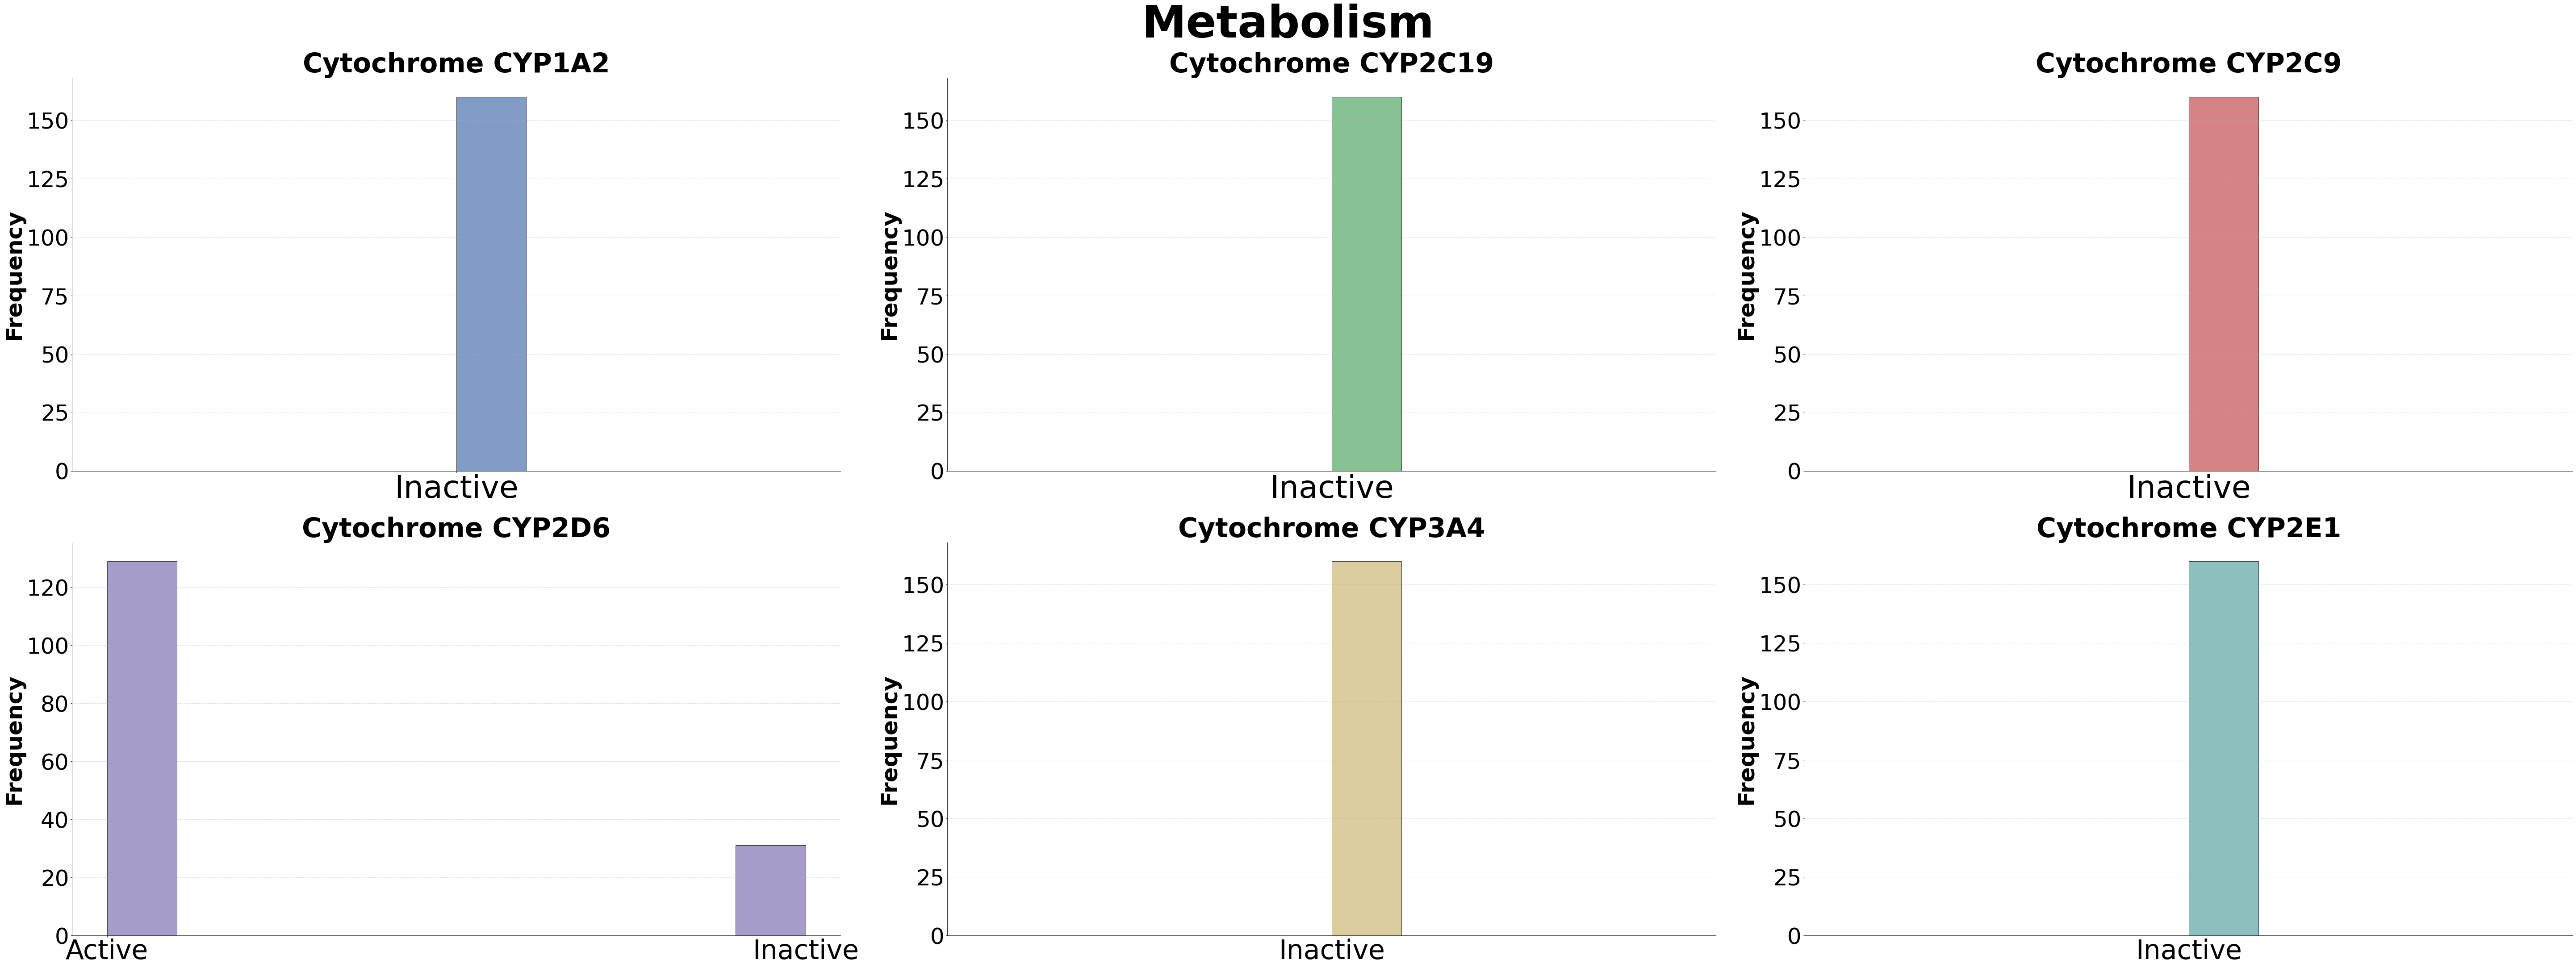

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 3, figsize=(80, 30), constrained_layout=True)

columns = [
'Cytochrome CYP1A2',
'Cytochrome CYP2C19',
'Cytochrome CYP2C9',
'Cytochrome CYP2D6',
'Cytochrome CYP3A4',
'Cytochrome CYP2E1'
]

titles = [
   'Cytochrome CYP1A2',
'Cytochrome CYP2C19',
'Cytochrome CYP2C9',
'Cytochrome CYP2D6',
'Cytochrome CYP3A4',
'Cytochrome CYP2E1'
]
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974','#5DA5A4']
col_no = 0
for i in range(3):
    ax[0,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[0,i].set_title(titles[col_no], fontsize=60,fontweight='bold')
#     ax[0,i].set_xlabel('Class', fontsize=60)
    ax[0,i].set_ylabel('Frequency', fontsize=50,fontweight='bold')
    ax[0,i].tick_params(axis='x', labelsize=70) # Change 12 to your desired size
    ax[0,i].tick_params(axis='y',labelsize=50)

    ax[0,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[0,i].spines['top'].set_visible(False)
    ax[0,i].spines['right'].set_visible(False)
    col_no = col_no+1
col_no = 3
for i in range(3):
    ax[1,i].hist(
        d3_prediction[columns[col_no]],
        color = colors[col_no],
        edgecolor='black',
        alpha=0.7
    )    
    ax[1,i].set_title(titles[col_no], fontsize=60,fontweight='bold')
#     ax[1,i].set_xlabel('Class', fontsize=50)
    ax[1,i].set_ylabel('Frequency', fontsize=50,fontweight='bold')
    ax[1,i].tick_params(axis='x', labelsize=60) # Change 12 to your desired size
    ax[1,i].tick_params(axis='y',labelsize=50)

    ax[1,i].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Remove top and right spines for cleaner look
    ax[1,i].spines['top'].set_visible(False)
    ax[1,i].spines['right'].set_visible(False)
    col_no = col_no+1

# Optional overall title
fig.suptitle('Metabolism', fontsize=100,fontweight='bold')
plt.savefig("mir155_toxicity/toxicity_plot_mir155_Metabolism.png")
plt.show()